In [ ]:
!pip install -U ipywidgets

In [ ]:
!pip install -U datasets

In [ ]:
from datasets import load_dataset

dataset = load_dataset("thu-coai/esconv")

In [ ]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 910
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 195
    })
    test: Dataset({
        features: ['text'],
        num_rows: 195
    })
})


In [ ]:
print(dataset["train"][0])

{'text': '{"experience_type": "Current Experience", "emotion_type": "anxiety", "problem_type": "job crisis", "situation": "I am on short term disability and I am afraid I will lose my job if I don\'t go back soon.", "survey_score": {"seeker": {"initial_emotion_intensity": "3", "empathy": "5", "relevance": "5", "final_emotion_intensity": "2"}, "supporter": {"relevance": "5"}}, "dialog": [{"text": "Hello good afternoon.", "speaker": "usr"}, {"text": "Hi, good afternoon.", "speaker": "sys", "strategy": "Question"}, {"text": "I\'m feeling anxious that I am going to lose my job.", "speaker": "usr"}, {"text": "Losing a job is always anxious.", "speaker": "sys", "strategy": "Reflection of feelings"}, {"text": "I hope I don\'t.", "speaker": "usr"}, {"text": "Why do you think you will lose your job?", "speaker": "sys", "strategy": "Question"}, {"text": "I am on short term disability and I am not ready to go back to work yet but I do not have any job protection.", "speaker": "usr"}, {"text": "Oh

In [ ]:
import pandas as pd

df = dataset["train"].to_pandas()

In [ ]:
df.shape

(910, 1)

In [ ]:
df.columns

Index(['text'], dtype='str')

In [ ]:
df.head()

,text
0,"{""experience_type"": ""Current Experience"", ""emo..."
1,"{""experience_type"": ""Current Experience"", ""emo..."
2,"{""experience_type"": ""Current Experience"", ""emo..."
3,"{""experience_type"": ""Current Experience"", ""emo..."
4,"{""experience_type"": ""Previous Experience"", ""em..."


In [ ]:
df.to_csv("ESConv_raw.csv", index=False, encoding="utf-8-sig")

In [ ]:
import os

print(os.path.abspath("ESConv_raw.csv"))

C:\Users\Partha Sen\ESConv_raw.csv


In [ ]:
import pandas as pd
import json
import re
import ast
import os

df_raw = pd.read_csv("ESConv_raw.csv")

print(df_raw.shape)
print(df_raw.columns)
df_raw.head()

(910, 1)
Index(['text'], dtype='str')


,text
0,"{""experience_type"": ""Current Experience"", ""emo..."
1,"{""experience_type"": ""Current Experience"", ""emo..."
2,"{""experience_type"": ""Current Experience"", ""emo..."
3,"{""experience_type"": ""Current Experience"", ""emo..."
4,"{""experience_type"": ""Previous Experience"", ""em..."


In [ ]:
def parse_json_text(x):
    try:
        if pd.isna(x):
            return None
        return json.loads(x)
    except Exception:
        try:
            return ast.literal_eval(x)
        except Exception:
            return None


parsed_data = df_raw["text"].apply(parse_json_text)

print("Total records:", len(parsed_data))
print("Successfully parsed:", parsed_data.notna().sum())
print("Failed:", parsed_data.isna().sum())

Total records: 910
Successfully parsed: 910
Failed: 0


In [ ]:
conversation_records = []

for i, record in enumerate(parsed_data):

    if record is None:
        continue

    survey = record.get("survey_score", {})
    seeker_score = survey.get("seeker", {})
    supporter_score = survey.get("supporter", {})

    dialog = record.get("dialog", [])

    # Count valid dialogue messages
    valid_dialog = [
        turn for turn in dialog
        if isinstance(turn, dict) and turn.get("text")
    ]

    conversation_records.append({
        "conversation_id": i + 1,
        "experience_type": record.get("experience_type"),
        "emotion_type": record.get("emotion_type"),
        "problem_type": record.get("problem_type"),
        "situation": record.get("situation"),
        "initial_emotion_intensity": seeker_score.get("initial_emotion_intensity"),
        "final_emotion_intensity": seeker_score.get("final_emotion_intensity"),
        "seeker_empathy_score": seeker_score.get("empathy"),
        "seeker_relevance_score": seeker_score.get("relevance"),
        "supporter_relevance_score": supporter_score.get("relevance"),
        "number_of_turns": len(valid_dialog)
    })


df_conversations = pd.DataFrame(conversation_records)

print(df_conversations.shape)
df_conversations.head()

(910, 11)


,conversation_id,experience_type,emotion_type,problem_type,situation,initial_emotion_intensity,final_emotion_intensity,seeker_empathy_score,seeker_relevance_score,supporter_relevance_score,number_of_turns
0,1,Current Experience,anxiety,job crisis,I am on short term disability and I am afraid ...,3,2,5,5,5,25
1,2,Current Experience,depression,ongoing depression,I have been in a depression since my father di...,4,3,4,5,5,31
2,3,Current Experience,anxiety,job crisis,I would like to get an online job but it is v...,5,3,5,4,3,49
3,4,Current Experience,depression,breakup with partner,turned in ex gf to cps for giving her kids drugs.,5,4,3,2,5,23
4,5,Previous Experience,disgust,problems with friends,one of my friends cheated on her boyfriend.,5,2,5,5,5,31


In [ ]:
def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Remove excessive whitespace
    text = re.sub(r"\s+", " ", text)

    # Remove leading/trailing spaces
    text = text.strip()

    return text


df_conversations["situation"] = (
    df_conversations["situation"]
    .apply(clean_text)
)

In [ ]:
turn_records = []

for i, record in enumerate(parsed_data):

    if record is None:
        continue

    conversation_id = i + 1

    for turn_number, turn in enumerate(record.get("dialog", []), start=1):

        if not isinstance(turn, dict):
            continue

        message = turn.get("text")

        if not message:
            continue

        message = clean_text(message)

        if not message:
            continue

        speaker = turn.get("speaker", "")

        # Convert dataset labels into understandable labels
        if speaker == "usr":
            speaker_clean = "user"
        elif speaker == "sys":
            speaker_clean = "assistant"
        else:
            speaker_clean = speaker

        turn_records.append({
            "conversation_id": conversation_id,
            "turn_number": turn_number,
            "speaker": speaker_clean,
            "message": message,
            "strategy": turn.get("strategy", "")
        })


df_turns = pd.DataFrame(turn_records)

print(df_turns.shape)
df_turns.head(20)

(26648, 5)


,conversation_id,turn_number,speaker,message,strategy
0,1,1,user,Hello good afternoon.,
1,1,2,assistant,"Hi, good afternoon.",Question
2,1,3,user,I'm feeling anxious that I am going to lose my...,
3,1,4,assistant,Losing a job is always anxious.,Reflection of feelings
4,1,5,user,I hope I don't.,
5,1,6,assistant,Why do you think you will lose your job?,Question
6,1,7,user,I am on short term disability and I am not rea...,
7,1,8,assistant,Oh so your job is not protected and your short...,Restatement or Paraphrasing
8,1,9,user,"It's not ending yet, but no my job is not prot...",
9,1,10,user,"you have to have been here for a year, and I s...",


In [ ]:
metadata = df_conversations[
    [
        "conversation_id",
        "experience_type",
        "emotion_type",
        "problem_type",
        "situation"
    ]
]

df_turns = df_turns.merge(
    metadata,
    on="conversation_id",
    how="left"
)

print(df_turns.head(20))

    conversation_id  turn_number    speaker  \
0                 1            1       user   
1                 1            2  assistant   
2                 1            3       user   
3                 1            4  assistant   
4                 1            5       user   
5                 1            6  assistant   
6                 1            7       user   
7                 1            8  assistant   
8                 1            9       user   
9                 1           10       user   
10                1           11       user   
11                1           12  assistant   
12                1           13       user   
13                1           14  assistant   
14                1           15       user   
15                1           16       user   
16                1           17  assistant   
17                1           18       user   
18                1           19       user   
19                1           20  assistant   

            

In [ ]:
df_conversations = df_conversations.drop_duplicates(
    subset=["situation", "problem_type", "emotion_type"]
)

df_turns = df_turns.drop_duplicates()

print("Conversations:", len(df_conversations))
print("Dialogue turns:", len(df_turns))

Conversations: 908
Dialogue turns: 26648


In [ ]:
print(df_conversations.isnull().sum())

conversation_id                0
experience_type                0
emotion_type                   0
problem_type                   0
situation                      0
initial_emotion_intensity      0
final_emotion_intensity      110
seeker_empathy_score         110
seeker_relevance_score       110
supporter_relevance_score    133
number_of_turns                0
dtype: int64


In [ ]:
print(df_turns.isnull().sum())

conversation_id    0
turn_number        0
speaker            0
message            0
strategy           0
experience_type    0
emotion_type       0
problem_type       0
situation          0
dtype: int64


In [ ]:
categorical_columns = [
    "experience_type",
    "emotion_type",
    "problem_type"
]

for col in categorical_columns:
    df_conversations[col] = (
        df_conversations[col]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
    )

In [ ]:
df_turns["strategy"] = (
    df_turns["strategy"]
    .fillna("")
    .astype(str)
    .str.strip()
)

In [ ]:
df_conversations.to_csv(
    "ESConv_Clean_Conversations.csv",
    index=False,
    encoding="utf-8-sig"
)

df_turns.to_csv(
    "ESConv_Clean_Turns.csv",
    index=False,
    encoding="utf-8-sig"
)

In [ ]:
df_conversations.to_csv(
    "ESConv_Clean_Conversations.csv",
    index=False,
    encoding="utf-8-sig"
)

df_turns.to_csv(
    "ESConv_Clean_Turns.csv",
    index=False,
    encoding="utf-8-sig"
)

In [ ]:
print("Conversation CSV:")
print(os.path.abspath("ESConv_Clean_Conversations.csv"))

print("\nTurn-level CSV:")
print(os.path.abspath("ESConv_Clean_Turns.csv"))

Conversation CSV:
C:\Users\Partha Sen\ESConv_Clean_Conversations.csv

Turn-level CSV:
C:\Users\Partha Sen\ESConv_Clean_Turns.csv


In [ ]:
import pandas as pd

# Load the datasets
conversations = pd.read_csv("ESConv_Clean_Conversations.csv")
turns = pd.read_csv("ESConv_Clean_Turns.csv")

print("Conversations dataset:")
print(conversations.shape)

print("\nTurns dataset:")
print(turns.shape)

Conversations dataset:
(908, 11)

Turns dataset:
(26648, 9)


In [ ]:
conversation_id = 1

# Get conversation-level information
info = conversations[
    conversations["conversation_id"] == conversation_id
].iloc[0]

print("=" * 70)
print(f"CONVERSATION ID: {conversation_id}")
print("=" * 70)

print(f"Experience Type: {info['experience_type']}")
print(f"Emotion Type: {info['emotion_type']}")
print(f"Problem Type: {info['problem_type']}")
print(f"Situation: {info['situation']}")

print("\n--- Evaluation Scores ---")
print(f"Initial Emotion Intensity: {info['initial_emotion_intensity']}")
print(f"Final Emotion Intensity: {info['final_emotion_intensity']}")
print(f"Seeker Empathy Score: {info['seeker_empathy_score']}")
print(f"Seeker Relevance Score: {info['seeker_relevance_score']}")
print(f"Supporter Relevance Score: {info['supporter_relevance_score']}")

print("\n--- Conversation ---")

conversation = turns[
    turns["conversation_id"] == conversation_id
]

for _, row in conversation.iterrows():
    speaker = row["speaker"].upper()
    message = row["message"]

    print(f"\n{speaker}: {message}")

    if pd.notna(row["strategy"]) and row["strategy"] != "":
        print(f"[Strategy: {row['strategy']}]")

CONVERSATION ID: 1
Experience Type: Current Experience
Emotion Type: anxiety
Problem Type: job crisis
Situation: I am on short term disability and I am afraid I will lose my job if I don't go back soon.

--- Evaluation Scores ---
Initial Emotion Intensity: 3
Final Emotion Intensity: 2.0
Seeker Empathy Score: 5.0
Seeker Relevance Score: 5.0
Supporter Relevance Score: 5.0

--- Conversation ---

USER: Hello good afternoon.

ASSISTANT: Hi, good afternoon.
[Strategy: Question]

USER: I'm feeling anxious that I am going to lose my job.

ASSISTANT: Losing a job is always anxious.
[Strategy: Reflection of feelings]

USER: I hope I don't.

ASSISTANT: Why do you think you will lose your job?
[Strategy: Question]

USER: I am on short term disability and I am not ready to go back to work yet but I do not have any job protection.

ASSISTANT: Oh so your job is not protected and your short term disability will end soon? Is that correct?
[Strategy: Restatement or Paraphrasing]

USER: It's not ending y

In [ ]:
# Check your actual dataframe name and columns
print(df_turns.columns.tolist())
print(df_turns.head(3))

['conversation_id', 'turn_number', 'speaker', 'message', 'strategy', 'experience_type', 'emotion_type', 'problem_type', 'situation']
   conversation_id  turn_number    speaker  \
0                1            1       user   
1                1            2  assistant   
2                1            3       user   

                                             message  strategy  \
0                              Hello good afternoon.             
1                                Hi, good afternoon.  Question   
2  I'm feeling anxious that I am going to lose my...             

      experience_type emotion_type problem_type  \
0  Current Experience      anxiety   job crisis   
1  Current Experience      anxiety   job crisis   
2  Current Experience      anxiety   job crisis   

                                           situation  
0  I am on short term disability and I am afraid ...  
1  I am on short term disability and I am afraid ...  
2  I am on short term disability and I am afrai

In [ ]:
# FIXED - column is 'message' not 'message_text'
df_turns['msg_length_words'] = (
    df_turns['message']
    .astype(str)
    .str.strip()
    .apply(lambda x: len(x.split()))
)

print("Done. Sample:")
print(df_turns[['message', 'msg_length_words']].head(10))

Done. Sample:
                                             message  msg_length_words
0                              Hello good afternoon.                 3
1                                Hi, good afternoon.                 3
2  I'm feeling anxious that I am going to lose my...                11
3                    Losing a job is always anxious.                 6
4                                    I hope I don't.                 4
5           Why do you think you will lose your job?                 9
6  I am on short term disability and I am not rea...                25
7  Oh so your job is not protected and your short...                18
8  It's not ending yet, but no my job is not prot...                33
9  you have to have been here for a year, and I s...                14


In [ ]:
print(df.columns.tolist())
print(df.head())
print(df.shape)

['text']
                                                text
0  {"experience_type": "Current Experience", "emo...
1  {"experience_type": "Current Experience", "emo...
2  {"experience_type": "Current Experience", "emo...
3  {"experience_type": "Current Experience", "emo...
4  {"experience_type": "Previous Experience", "em...
(910, 1)


In [ ]:
print([repr(column) for column in df.columns])

["'text'"]


In [ ]:
df.columns = (
    df.columns
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['text']


In [ ]:
conv_df.columns = (
    conv_df.columns
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

turns_df.columns = (
    turns_df.columns
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(turns_df.columns.tolist())

['conversation_id', 'turn_number', 'speaker', 'message', 'strategy', 'experience_type', 'emotion_type', 'problem_type', 'situation', 'msg_length_words', 'msg_length_chars']


In [ ]:
import pandas as pd

conv_df = pd.read_csv("ESConv_Clean_Conversations.csv")
turns_df = pd.read_csv("ESConv_Clean_Turns.csv")

print(conv_df.columns.tolist())
print(turns_df.columns.tolist())

['conversation_id', 'experience_type', 'emotion_type', 'problem_type', 'situation', 'initial_emotion_intensity', 'final_emotion_intensity', 'seeker_empathy_score', 'seeker_relevance_score', 'supporter_relevance_score', 'number_of_turns']
['conversation_id', 'turn_number', 'speaker', 'message', 'strategy', 'experience_type', 'emotion_type', 'problem_type', 'situation']


In [ ]:
conv_df.columns = (
    conv_df.columns
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

turns_df.columns = (
    turns_df.columns
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(turns_df.columns.tolist())

['conversation_id', 'turn_number', 'speaker', 'message', 'strategy', 'experience_type', 'emotion_type', 'problem_type', 'situation']


In [ ]:
turns_df["message"] = turns_df["message"].fillna("").astype(str)

turns_df["msg_length_words"] = (
    turns_df["message"]
    .apply(lambda text: len(text.split()))
)

turns_df["msg_length_chars"] = (
    turns_df["message"]
    .apply(len)
)

turns_df[
    ["conversation_id", "turn_number", "speaker",
     "message", "msg_length_words"]
].head()

,conversation_id,turn_number,speaker,message,msg_length_words
0,1,1,user,Hello good afternoon.,3
1,1,2,assistant,"Hi, good afternoon.",3
2,1,3,user,I'm feeling anxious that I am going to lose my...,11
3,1,4,assistant,Losing a job is always anxious.,6
4,1,5,user,I hope I don't.,4


In [ ]:
turns_df["speaker"] = (
    turns_df["speaker"]
    .astype(str)
    .str.strip()
    .str.lower()
)

user_mask = turns_df["speaker"].isin(["user", "seeker"])
assistant_mask = turns_df["speaker"].isin(["assistant", "supporter"])

print(turns_df["speaker"].value_counts())

speaker
user         13889
assistant    12759
Name: count, dtype: int64


In [ ]:
user_turn_count = (
    turns_df[user_mask]
    .groupby("conversation_id")
    .size()
    .rename("user_turn_count")
)

In [ ]:
assistant_turn_count = (
    turns_df[assistant_mask]
    .groupby("conversation_id")
    .size()
    .rename("assistant_turn_count")
)

In [ ]:
total_turn_count = (
    turns_df
    .groupby("conversation_id")
    .size()
    .rename("total_turn_count")
)

behavior_df = pd.concat(
    [
        user_turn_count,
        assistant_turn_count,
        total_turn_count
    ],
    axis=1
).fillna(0)

behavior_df["engagement_ratio"] = (
    behavior_df["user_turn_count"]
    / behavior_df["total_turn_count"]
)

In [ ]:
avg_user_length = (
    turns_df[user_mask]
    .groupby("conversation_id")["msg_length_words"]
    .mean()
    .rename("avg_user_msg_length")
)

behavior_df = behavior_df.join(avg_user_length)

In [ ]:
avg_assistant_length = (
    turns_df[assistant_mask]
    .groupby("conversation_id")["msg_length_words"]
    .mean()
    .rename("avg_assistant_msg_length")
)

behavior_df = behavior_df.join(avg_assistant_length)

In [ ]:
user_length_std = (
    turns_df[user_mask]
    .groupby("conversation_id")["msg_length_words"]
    .std()
    .rename("user_msg_length_std")
)

behavior_df = behavior_df.join(user_length_std)

In [ ]:
last_user_turn = (
    turns_df[user_mask]
    .groupby("conversation_id")["turn_number"]
    .max()
    .rename("last_user_turn")
)

behavior_df = behavior_df.join(last_user_turn)

In [ ]:
last_turn = (
    turns_df
    .sort_values(["conversation_id", "turn_number"])
    .groupby("conversation_id")
    .tail(1)
    .set_index("conversation_id")["speaker"]
    .rename("last_speaker")
)

behavior_df = behavior_df.join(last_turn)

behavior_df["ended_by_user"] = (
    behavior_df["last_speaker"] == "user"
).astype(int)

In [ ]:
df = df.reset_index(names="conversation_id")

In [ ]:
print(df.index.name)          # should show 'conversation_id'
print(df.columns.tolist())    # conversation_id will NOT be in this list

None
['conversation_id', 'text']


In [ ]:
df = df.reset_index()

In [ ]:

# Cell 1 — See the shape
print("Shape:", behavior_df.shape)
print("\nColumns:", behavior_df.columns.tolist())

Shape: (910, 10)

Columns: ['user_turn_count', 'assistant_turn_count', 'total_turn_count', 'engagement_ratio', 'avg_user_msg_length', 'avg_assistant_msg_length', 'user_msg_length_std', 'last_user_turn', 'last_speaker', 'ended_by_user']


In [ ]:
df = df.reset_index()

In [ ]:
# Cell 1 — See the shape
print("Shape:", behavior_df.shape)
print("\nColumns:", behavior_df.columns.tolist())

Shape: (910, 10)

Columns: ['user_turn_count', 'assistant_turn_count', 'total_turn_count', 'engagement_ratio', 'avg_user_msg_length', 'avg_assistant_msg_length', 'user_msg_length_std', 'last_user_turn', 'last_speaker', 'ended_by_user']


In [ ]:
# Cell 2 — See first few rows
behavior_df.head(10)

,user_turn_count,assistant_turn_count,total_turn_count,engagement_ratio,avg_user_msg_length,avg_assistant_msg_length,user_msg_length_std,last_user_turn,last_speaker,ended_by_user
conversation_id,,,,,,,,,,
1,14,11,25,0.560000,21.000000,11.727273,12.618667,24,assistant,0
2,15,16,31,0.483871,16.933333,21.625000,10.381761,31,user,1
3,21,28,49,0.428571,7.285714,11.392857,5.451081,48,assistant,0
4,13,10,23,0.565217,20.230769,21.800000,20.212017,22,assistant,0
5,16,15,31,0.516129,10.875000,13.933333,5.714018,28,assistant,0
6,20,13,33,0.606061,16.900000,17.769231,8.914211,33,user,1
7,10,10,20,0.500000,16.900000,16.000000,9.122012,20,user,1
8,10,10,20,0.500000,13.600000,17.400000,6.040603,20,user,1
9,12,13,25,0.480000,23.333333,17.769231,10.696927,23,assistant,0


In [ ]:
# Cell 3 — Check for missing values
behavior_df.isnull().sum()

user_turn_count             0
assistant_turn_count        0
total_turn_count            0
engagement_ratio            0
avg_user_msg_length         0
avg_assistant_msg_length    0
user_msg_length_std         0
last_user_turn              0
last_speaker                0
ended_by_user               0
dtype: int64

In [ ]:
# Cell 4 — Basic statistics of all behavioral features
behavior_df.describe()

,user_turn_count,assistant_turn_count,total_turn_count,engagement_ratio,avg_user_msg_length,avg_assistant_msg_length,user_msg_length_std,last_user_turn,ended_by_user
count,910.000000,910.000000,910.000000,910.000000,910.000000,910.000000,910.000000,910.000000,910.000000
mean,15.262637,14.020879,29.283516,0.514805,15.598382,18.867818,10.127053,28.475824,0.332967
std,6.529297,4.491356,10.152352,0.065618,6.954770,7.247583,5.265053,10.129468,0.471534
min,6.000000,5.000000,16.000000,0.333333,4.428571,4.315789,2.118700,13.000000,0.000000
25%,11.000000,11.000000,23.000000,0.474013,10.500000,14.148810,6.457006,22.000000,0.000000
50%,13.000000,13.000000,26.000000,0.500000,14.281746,17.414286,8.940400,25.000000,0.000000
75%,17.000000,16.000000,32.000000,0.551724,19.000000,22.089015,12.491451,31.000000,1.000000
max,67.000000,53.000000,120.000000,0.827586,56.000000,68.200000,37.458967,119.000000,1.000000


In [ ]:
# Cell 5 — Check last_speaker values
print(behavior_df["last_speaker"].value_counts())
print("\nEnded by user count:", behavior_df["ended_by_user"].sum())

last_speaker
assistant    607
user         303
Name: count, dtype: int64

Ended by user count: 303


In [ ]:
!pip install scipy

In [ ]:
from scipy import stats

slopes = {}

for conv_id, group in turns_df[user_mask].groupby("conversation_id"):
    group = group.sort_values("turn_number")
    lengths = group["msg_length_words"].tolist()

    if len(lengths) >= 2:
        slope, _, _, _, _ = stats.linregress(
            range(len(lengths)), lengths
        )
        slopes[conv_id] = slope
    else:
        slopes[conv_id] = 0.0   # only 1 message, no slope

slope_series = pd.Series(slopes, name="msg_length_slope")
behavior_df = behavior_df.join(slope_series)

print("Slope added. Sample values:")
print(behavior_df["msg_length_slope"].describe())

Slope added. Sample values:
count    910.000000
mean      -0.090106
std        1.060757
min       -6.905594
25%       -0.550247
50%       -0.069538
75%        0.356085
max        5.454545
Name: msg_length_slope, dtype: float64


In [ ]:
# Dropout = user stopped early (last user turn was much before conversation ended)
behavior_df["dropout_gap"] = (
    behavior_df["total_turn_count"] - behavior_df["last_user_turn"]
)

# Binary dropout flag: gap > 2 means user likely dropped out
behavior_df["dropout_flag"] = (
    behavior_df["dropout_gap"] > 2
).astype(int)

print("Dropout distribution:")
print(behavior_df["dropout_flag"].value_counts())

Dropout distribution:
dropout_flag
0    894
1     16
Name: count, dtype: int64


In [ ]:
# Load your conversations file
conv_df = pd.read_csv("ESConv_Clean_Conversations.csv")

# Check column names first
print(conv_df.columns.tolist())
print(conv_df.head(3))

['conversation_id', 'experience_type', 'emotion_type', 'problem_type', 'situation', 'initial_emotion_intensity', 'final_emotion_intensity', 'seeker_empathy_score', 'seeker_relevance_score', 'supporter_relevance_score', 'number_of_turns']
   conversation_id     experience_type emotion_type        problem_type  \
0                1  Current Experience      anxiety          job crisis   
1                2  Current Experience   depression  ongoing depression   
2                3  Current Experience      anxiety          job crisis   

                                           situation  \
0  I am on short term disability and I am afraid ...   
1  I have been in a depression since my father di...   
2  I would like to get an online job but it is ve...   

   initial_emotion_intensity  final_emotion_intensity  seeker_empathy_score  \
0                          3                      2.0                   5.0   
1                          4                      3.0                   4.0   

In [ ]:
# Merge behavioral features with emotion labels
final_df = behavior_df.reset_index().merge(
    conv_df[[
        "conversation_id",
        "emotion_type",
        "problem_type",
        "initial_emotion_intensity",
        "final_emotion_intensity",
        "seeker_empathy_score",
        "number_of_turns"
    ]],
    on="conversation_id",
    how="left"
)

print("Final dataframe shape:", final_df.shape)
final_df.head()

Final dataframe shape: (910, 20)


,conversation_id,user_turn_count,assistant_turn_count,total_turn_count,engagement_ratio,avg_user_msg_length,avg_assistant_msg_length,user_msg_length_std,last_user_turn,last_speaker,ended_by_user,msg_length_slope,dropout_gap,dropout_flag,emotion_type,problem_type,initial_emotion_intensity,final_emotion_intensity,seeker_empathy_score,number_of_turns
0,1,14,11,25,0.560000,21.000000,11.727273,12.618667,24,assistant,0,1.683516,1,0,anxiety,job crisis,3.0,2.0,5.0,25.0
1,2,15,16,31,0.483871,16.933333,21.625000,10.381761,31,user,1,-0.821429,0,0,depression,ongoing depression,4.0,3.0,4.0,31.0
2,3,21,28,49,0.428571,7.285714,11.392857,5.451081,48,assistant,0,-0.128571,1,0,anxiety,job crisis,5.0,3.0,5.0,49.0
3,4,13,10,23,0.565217,20.230769,21.800000,20.212017,22,assistant,0,-3.576923,1,0,depression,breakup with partner,5.0,4.0,3.0,23.0
4,5,16,15,31,0.516129,10.875000,13.933333,5.714018,28,assistant,0,-0.523529,3,1,disgust,problems with friends,5.0,2.0,5.0,31.0


In [ ]:
!pip install matplotlib

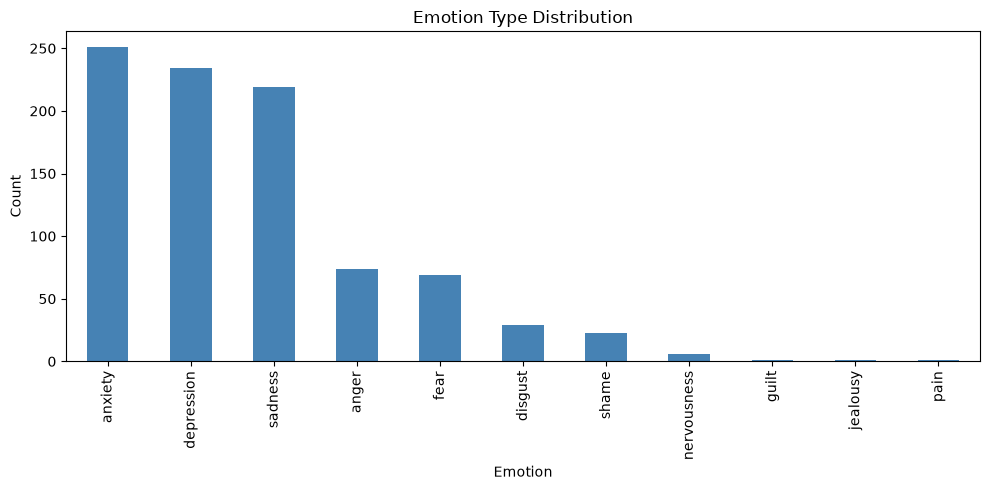

emotion_type
anxiety        251
depression     234
sadness        219
anger           74
fear            69
disgust         29
shame           23
nervousness      6
guilt            1
jealousy         1
pain             1
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt

# Emotion type distribution
final_df["emotion_type"].value_counts().plot(
    kind="bar",
    color="steelblue",
    figsize=(10, 5),
    title="Emotion Type Distribution"
)
plt.xlabel("Emotion")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print(final_df["emotion_type"].value_counts())

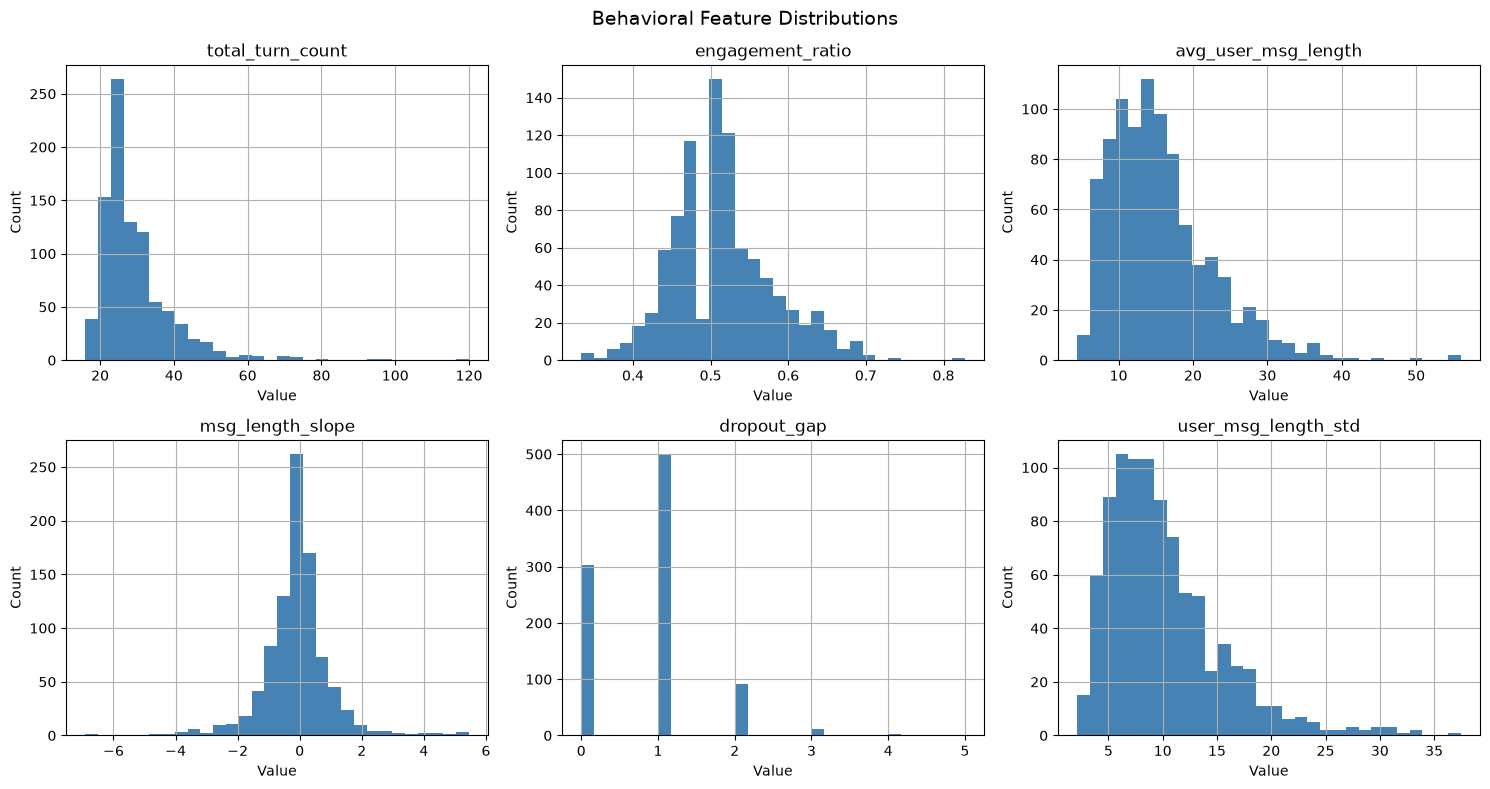

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

features = [
    "total_turn_count",
    "engagement_ratio",
    "avg_user_msg_length",
    "msg_length_slope",
    "dropout_gap",
    "user_msg_length_std"
]

for ax, feat in zip(axes.flatten(), features):
    final_df[feat].dropna().hist(bins=30, ax=ax, color="steelblue")
    ax.set_title(feat)
    ax.set_xlabel("Value")
    ax.set_ylabel("Count")

plt.suptitle("Behavioral Feature Distributions", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
!pip install scikit-learn

In [ ]:
# Encode emotion labels as numbers
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
final_df["emotion_encoded"] = le.fit_transform(
    final_df["emotion_type"].fillna("unknown")
)

print("Emotion encoding map:")
for i, cls in enumerate(le.classes_):
    print(f"  {i} → {cls}")

Emotion encoding map:
  0 → anger
  1 → anxiety
  2 → depression
  3 → disgust
  4 → fear
  5 → guilt
  6 → jealousy
  7 → nervousness
  8 → pain
  9 → sadness
  10 → shame
  11 → unknown


In [ ]:
!pip install seaborn

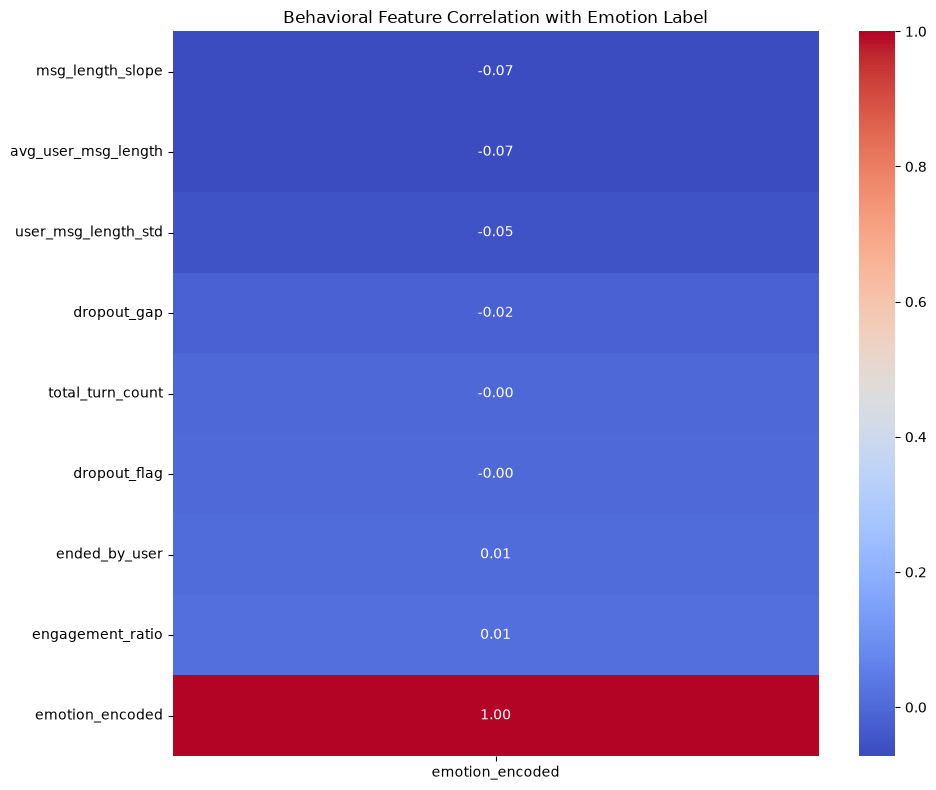

In [ ]:
# Correlation of behavioral features with emotion label
behavioral_cols = [
    "total_turn_count",
    "engagement_ratio",
    "avg_user_msg_length",
    "msg_length_slope",
    "dropout_flag",
    "dropout_gap",
    "user_msg_length_std",
    "ended_by_user"
]

corr = final_df[behavioral_cols + ["emotion_encoded"]].corr()

import seaborn as sns
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr[["emotion_encoded"]].sort_values("emotion_encoded"),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Behavioral Feature Correlation with Emotion Label")
plt.tight_layout()
plt.show()

In [ ]:
final_df.to_csv("behavioral_features_final.csv", index=False)
print("Saved! Shape:", final_df.shape)
print("\nAll columns:")
print(final_df.columns.tolist())

Saved! Shape: (910, 21)

All columns:
['conversation_id', 'user_turn_count', 'assistant_turn_count', 'total_turn_count', 'engagement_ratio', 'avg_user_msg_length', 'avg_assistant_msg_length', 'user_msg_length_std', 'last_user_turn', 'last_speaker', 'ended_by_user', 'msg_length_slope', 'dropout_gap', 'dropout_flag', 'emotion_type', 'problem_type', 'initial_emotion_intensity', 'final_emotion_intensity', 'seeker_empathy_score', 'number_of_turns', 'emotion_encoded']


In [ ]:
# Keep only emotions with enough samples (at least 20)
emotion_counts = final_df["emotion_type"].value_counts()
print(emotion_counts)

emotion_type
anxiety        251
depression     234
sadness        219
anger           74
fear            69
disgust         29
shame           23
nervousness      6
guilt            1
jealousy         1
pain             1
Name: count, dtype: int64


In [ ]:
# Define which to keep
valid_emotions = emotion_counts[emotion_counts >= 20].index.tolist()
print("\nKeeping these emotions:", valid_emotions)


Keeping these emotions: ['anxiety', 'depression', 'sadness', 'anger', 'fear', 'disgust', 'shame']


In [ ]:
# Filter dataframe
final_df_clean = final_df[
    final_df["emotion_type"].isin(valid_emotions)
].copy()

print("\nBefore filtering:", len(final_df))
print("After filtering:", len(final_df_clean))


Before filtering: 910
After filtering: 899


In [ ]:
# Re-encode labels
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
final_df_clean["emotion_encoded"] = le.fit_transform(
    final_df_clean["emotion_type"]
)

print("\nFinal emotion classes:")
for i, cls in enumerate(le.classes_):
    print(f"  {i} → {cls}")


Final emotion classes:
  0 → anger
  1 → anxiety
  2 → depression
  3 → disgust
  4 → fear
  5 → sadness
  6 → shame
